# Proyecto Primer Parcial — Aporte individual

**Estudiante:** Jhon Franklin Mejía Castro  
**Grupo:** D  
**Paralelo:** CDDEIA-ELNO-4-2  
**Responsabilidad:** Supuestos, Ridge/Lasso e integración  
**Dataset:** `student-mat.csv` (395 estudiantes)


## Preparación común para ejecutar de forma independiente
Estas celdas de configuración y carga de datos son compartidas como apoyo técnico; la sección atribuible a este integrante comienza más abajo.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression, RidgeCV, LassoCV
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             accuracy_score, precision_score, recall_score, confusion_matrix)
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

SEMILLA = 2026
pd.set_option('display.max_columns', 40)
sns.set_theme(style='whitegrid', context='notebook')
print('Bibliotecas cargadas; semilla:', SEMILLA)

/home/oai/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-bvnq1jyp because there was an issue with the default path (/home/oai/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Bibliotecas cargadas; semilla: 2026


In [ ]:
rutas = [Path('student-mat.csv'), Path('data/student-mat.csv'), Path('/content/student-mat.csv')]
ruta_csv = next((p for p in rutas if p.is_file()), None)
if ruta_csv is None:
    raise FileNotFoundError('Coloca student-mat.csv junto al notebook o en data/. No se modificó el dataset.')
df_original = pd.read_csv(ruta_csv, sep=',')
assert df_original.shape == (395, 33), f'Se esperaban 395 filas y 33 columnas, recibido: {df_original.shape}'
assert {'G1','G2','G3','absences','studytime'}.issubset(df_original.columns)
print('Archivo:', ruta_csv, '| Filas:', df_original.shape[0], '| Columnas:', df_original.shape[1])
display(df_original.head())

Archivo: student-mat.csv | Filas: 395 | Columnas: 33


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


In [3]:
datos = df_original.copy(deep=True)
rng = np.random.default_rng(SEMILLA)
for variable in ['absences','studytime']:
    posiciones = rng.choice(datos.index.to_numpy(), size=round(0.05 * len(datos)), replace=False)
    datos.loc[posiciones, variable] = np.nan
print('Nulos después de introducir el 5 % de forma reproducible:')
display(datos[['absences','studytime']].isna().sum().to_frame('nulos'))
q1, q3 = df_original['absences'].quantile([0.25, 0.75]); iqr = q3-q1
lim_inf, lim_sup = q1 - 1.5*iqr, q3 + 1.5*iqr
atipicos = df_original['absences'].lt(lim_inf) | df_original['absences'].gt(lim_sup)
print(f'Outliers IQR en absences: {atipicos.sum()} | Límites: {lim_inf:.1f} y {lim_sup:.1f}')
print('Decisión: conservarlos. Son ausencias posibles; eliminarlos sin evidencia podría sesgar el análisis.')

Nulos después de introducir el 5 % de forma reproducible:


,nulos
absences,20
studytime,20


Outliers IQR en absences: 15 | Límites: -12.0 y 20.0
Decisión: conservarlos. Son ausencias posibles; eliminarlos sin evidencia podría sesgar el análisis.


In [4]:
columnas_A = [c for c in datos.columns if c != 'G3']
columnas_B = [c for c in datos.columns if c not in {'G1','G2','G3'}]
objetivo_reg = datos['G3']
objetivo_aprueba = (datos['G3'] >= 10).astype(int)
# Estratificación por aprobación: mantiene una composición semejante en ambas particiones.
idx_entrenamiento, idx_prueba = train_test_split(
    np.arange(len(datos)), test_size=0.20, random_state=SEMILLA, stratify=objetivo_aprueba
)
print('Entrenamiento:', len(idx_entrenamiento), '| Prueba:', len(idx_prueba))

def construir_preprocesador(columnas: list[str]) -> ColumnTransformer:
    explicativas = datos[columnas]
    numericas = explicativas.select_dtypes(include=np.number).columns.tolist()
    categoricas = explicativas.select_dtypes(exclude=np.number).columns.tolist()
    return ColumnTransformer(transformers=[
        ('numericas', Pipeline(steps=[
            ('imputar', SimpleImputer(strategy='median')),
            ('escalar', StandardScaler())
        ]), numericas),
        ('categoricas', Pipeline(steps=[
            ('imputar', SimpleImputer(strategy='most_frequent')),
            ('codificar', OneHotEncoder(handle_unknown='ignore', drop='first'))
        ]), categoricas)
    ], remainder='drop')

print('Modelo A:', len(columnas_A), 'variables originales; Modelo B:', len(columnas_B))

Entrenamiento: 316 | Prueba: 79
Modelo A: 32 variables originales; Modelo B: 30


,MSE,RMSE,R2
modelo,,,
Modelo A: con G1 y G2,2.7692,1.6641,0.8565
Modelo B: sin G1 y G2,16.9075,4.1119,0.1237


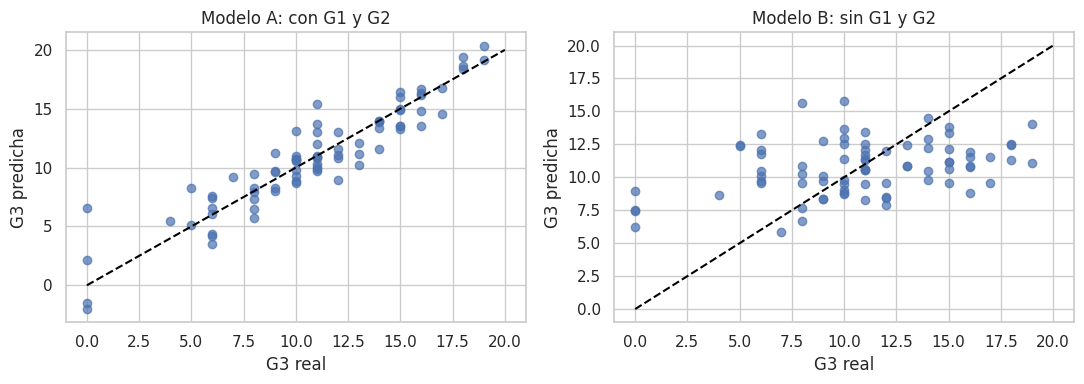

In [5]:
modelos_lineales = {}
predicciones_lineales = {}
filas_resultado = []
y_entrenamiento = objetivo_reg.iloc[idx_entrenamiento]
y_prueba = objetivo_reg.iloc[idx_prueba]
for nombre, columnas in [('Modelo A: con G1 y G2', columnas_A), ('Modelo B: sin G1 y G2', columnas_B)]:
    tuberia = Pipeline(steps=[('preprocesamiento', construir_preprocesador(columnas)),
                              ('regresion', LinearRegression())])
    tuberia.fit(datos.iloc[idx_entrenamiento][columnas], y_entrenamiento)
    pred = tuberia.predict(datos.iloc[idx_prueba][columnas])
    modelos_lineales[nombre] = tuberia; predicciones_lineales[nombre] = pred
    filas_resultado.append({'modelo': nombre, 'MSE': mean_squared_error(y_prueba,pred),
                            'RMSE': np.sqrt(mean_squared_error(y_prueba,pred)), 'R2': r2_score(y_prueba,pred)})
resultados_lineales = pd.DataFrame(filas_resultado).set_index('modelo').round(4)
display(resultados_lineales)
fig, ax = plt.subplots(1,2,figsize=(11,4))
for grafico,(nombre,pred) in zip(ax,predicciones_lineales.items()):
    grafico.scatter(y_prueba,pred,alpha=.7)
    grafico.plot([0,20],[0,20],ls='--',color='black')
    grafico.set_title(nombre);grafico.set_xlabel('G3 real');grafico.set_ylabel('G3 predicha')
plt.tight_layout();plt.show()

In [ ]:
pred_B = predicciones_lineales['Modelo B: sin G1 y G2']
mse_manual = np.mean((y_prueba.to_numpy() - pred_B)**2)
mse_sklearn = mean_squared_error(y_prueba, pred_B)
print('MSE manual (NumPy):',round(mse_manual,8))
print('MSE scikit-learn:',round(mse_sklearn,8))
assert np.isclose(mse_manual, mse_sklearn)
print('Comprobación correcta: los resultados coinciden.')

MSE manual (NumPy): 16.90745452
MSE scikit-learn: 16.90745452
Comprobación correcta: los resultados coinciden.


### Evaluación de cinco supuestos — Modelo B
Los supuestos se examinan con gráficas y pruebas de diagnóstico. Ningún gráfico prueba por sí solo causalidad. La independencia no queda demostrada por Durbin–Watson porque este dataset es transversal, no una serie temporal.

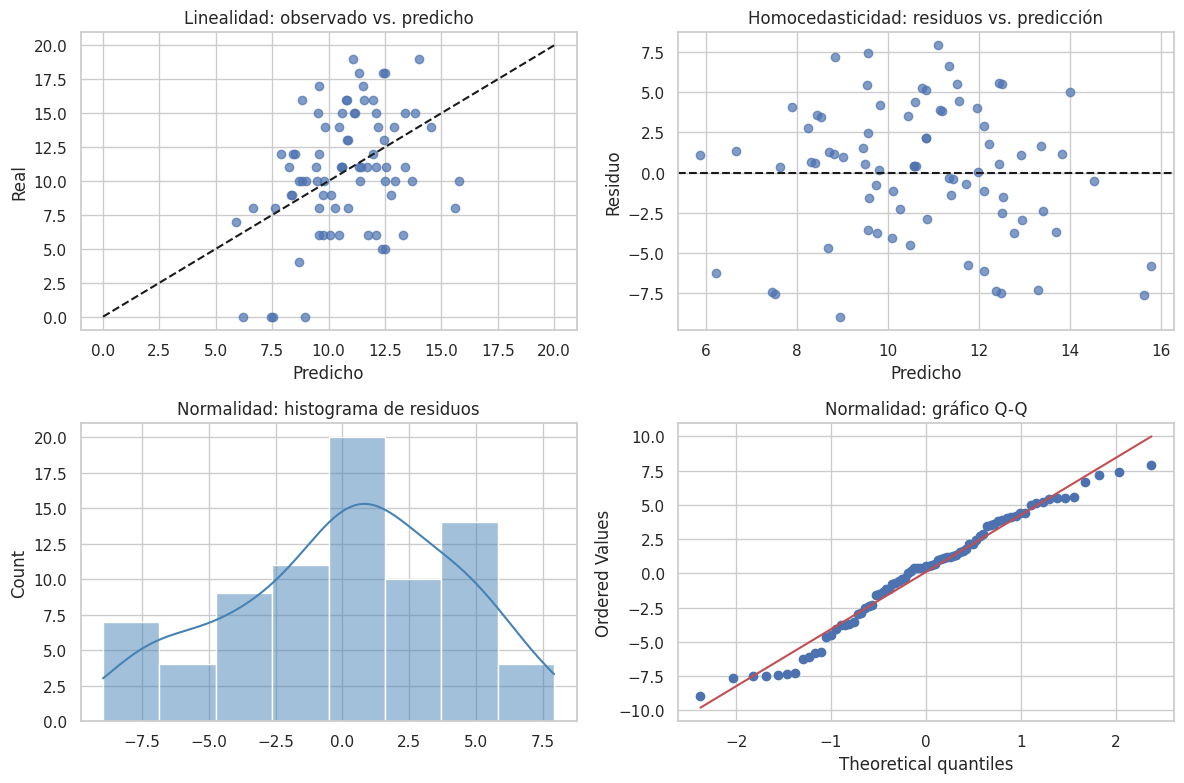

Durbin-Watson: 2.002 | Shapiro-Wilk p=0.0783 | Breusch-Pagan p=0.4968
Nota: estos contrastes orientan el diagnóstico; una muestra de 79 casos y datos transversales limitan la interpretación.


In [7]:
residuos_B = y_prueba.to_numpy() - pred_B
fig, ax = plt.subplots(2,2,figsize=(12,8))
ax[0,0].scatter(pred_B, y_prueba, alpha=.7);ax[0,0].plot([0,20],[0,20],'k--')
ax[0,0].set(title='Linealidad: observado vs. predicho',xlabel='Predicho',ylabel='Real')
ax[0,1].scatter(pred_B, residuos_B, alpha=.7);ax[0,1].axhline(0,color='k',ls='--')
ax[0,1].set(title='Homocedasticidad: residuos vs. predicción',xlabel='Predicho',ylabel='Residuo')
sns.histplot(residuos_B,kde=True,color='steelblue',ax=ax[1,0]);ax[1,0].set_title('Normalidad: histograma de residuos')
stats.probplot(residuos_B,dist='norm',plot=ax[1,1]);ax[1,1].set_title('Normalidad: gráfico Q-Q')
plt.tight_layout();plt.show()

dw = durbin_watson(residuos_B)
shapiro_p = stats.shapiro(residuos_B).pvalue
# Prueba de Breusch-Pagan: explicativas numéricas presentes en test; no se incluyen etiquetas de G3.
matriz_numerica = datos.iloc[idx_prueba][columnas_B].select_dtypes(include=np.number).copy()
matriz_numerica = matriz_numerica.fillna(matriz_numerica.median())
exog_bp = sm.add_constant(matriz_numerica,has_constant='add')
bp_lm,bp_p,bp_f,bp_fp = het_breuschpagan(residuos_B,exog_bp)
print(f'Durbin-Watson: {dw:.3f} | Shapiro-Wilk p={shapiro_p:.4f} | Breusch-Pagan p={bp_p:.4f}')
print('Nota: estos contrastes orientan el diagnóstico; una muestra de 79 casos y datos transversales limitan la interpretación.')

In [ ]:
mat_vif = datos.iloc[idx_entrenamiento][columnas_B].select_dtypes(include=np.number).copy()
mat_vif = mat_vif.fillna(mat_vif.median())
mat_vif = sm.add_constant(mat_vif,has_constant='add')
tabla_vif = pd.DataFrame({
    'variable': mat_vif.columns[1:],
    'VIF': [variance_inflation_factor(mat_vif.to_numpy(dtype=float), i)
            for i in range(1,mat_vif.shape[1])]
}).sort_values('VIF',ascending=False)
display(tabla_vif.round(3))
print('Alto VIF significa redundancia entre predictores; este análisis se limita a columnas numéricas originales.')

,variable,VIF
10,Walc,2.101
9,Dalc,1.896
2,Fedu,1.799
1,Medu,1.796
8,goout,1.325
5,failures,1.241
7,freetime,1.193
0,age,1.166
4,studytime,1.124
6,famrel,1.098


Alto VIF significa redundancia entre predictores; este análisis se limita a columnas numéricas originales.


**Lectura de los cinco supuestos:** (1) Linealidad: observar si real vs. predicho sigue la diagonal y si los residuos no muestran curvaturas; (2) independencia: no asumirla automáticamente; Durbin–Watson es descriptivo aquí y la pertenencia a escuelas puede generar dependencia; (3) homocedasticidad: revisar abanicos en residuos y el valor p de Breusch–Pagan; (4) normalidad: contrastar histograma, Q-Q y Shapiro; (5) multicolinealidad: comparar VIF, especialmente en variables correlacionadas. Un valor p menor a 0,05 sugiere evidencia contra el supuesto correspondiente, **no mide la magnitud del efecto**.

## Bonificación (+1): Ridge y Lasso frente al Modelo B
Se realiza la misma división, sin `G1` ni `G2`, con regularización calibrada exclusivamente sobre el conjunto de entrenamiento. Los coeficientes cero de Lasso se identifican tras el One-Hot Encoding.

In [9]:
alfas_ridge = np.logspace(-2,3,20)
alfas_lasso = np.logspace(-3,1,25)
modelos_extra = {
    'Ridge': RidgeCV(alphas=alfas_ridge),
    'Lasso': LassoCV(alphas=alfas_lasso,cv=5,random_state=SEMILLA,max_iter=20000)
}
extra=[]
for nombre,estimador in modelos_extra.items():
    pipeline=Pipeline([('preprocesamiento',construir_preprocesador(columnas_B)),('modelo',estimador)])
    pipeline.fit(datos.iloc[idx_entrenamiento][columnas_B],y_entrenamiento)
    pred=pipeline.predict(datos.iloc[idx_prueba][columnas_B])
    coefs=pipeline.named_steps['modelo'].coef_
    caracteristicas=pipeline.named_steps['preprocesamiento'].get_feature_names_out()
    seleccion_ceros=list(caracteristicas[np.abs(coefs)<1e-8])
    extra.append({'modelo':nombre,'R2':r2_score(y_prueba,pred),'RMSE':np.sqrt(mean_squared_error(y_prueba,pred)),
                  'alpha':pipeline.named_steps['modelo'].alpha_,'coeficientes_cero':len(seleccion_ceros)})
    if nombre=='Lasso':
        print('Variables transformadas eliminadas por Lasso (coeficientes 0):')
        print(', '.join(seleccion_ceros) if seleccion_ceros else 'Ninguna')
display(pd.DataFrame(extra).set_index('modelo').round(4))
print('Referencia: R2 del Modelo B sin regularización =',round(resultados_lineales.loc['Modelo B: sin G1 y G2','R2'],4))

Variables transformadas eliminadas por Lasso (coeficientes 0):
numericas__Fedu, numericas__studytime, numericas__famrel, numericas__freetime, numericas__Dalc, numericas__Walc, numericas__health, categoricas__school_MS, categoricas__address_U, categoricas__famsize_LE3, categoricas__Pstatus_T, categoricas__Mjob_health, categoricas__Mjob_other, categoricas__Mjob_services, categoricas__Mjob_teacher, categoricas__Fjob_health, categoricas__Fjob_other, categoricas__Fjob_services, categoricas__Fjob_teacher, categoricas__reason_home, categoricas__reason_other, categoricas__reason_reputation, categoricas__guardian_mother, categoricas__guardian_other, categoricas__schoolsup_yes, categoricas__famsup_yes, categoricas__paid_yes, categoricas__activities_yes, categoricas__nursery_yes, categoricas__higher_yes, categoricas__internet_yes


,R2,RMSE,alpha,coeficientes_cero
modelo,,,,
Ridge,0.1701,4.0015,88.5867,0
Lasso,0.1441,4.0637,0.2154,31


Referencia: R2 del Modelo B sin regularización = 0.1237


### Interpretación de la bonificación
En la partición utilizada, **Ridge** mejora el R² del Modelo B desde aproximadamente **0,124** hasta **0,170**; **Lasso** lo mejora hasta aproximadamente **0,144**. En ambos casos el rendimiento sigue siendo modesto: la regularización ayuda a controlar complejidad, pero no reemplaza la información que falta. Los coeficientes exactamente cero de Lasso se muestran en la salida de código y deben explicarse con cuidado porque varias columnas son categorías codificadas.